<a href="https://colab.research.google.com/github/sredhagopan/AI-ML-Lab/blob/main/Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## K-Means Clustering
### Date : 14 October 2026

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import silhouette_score, confusion_matrix, classification_report

# Load the dataset
df = pd.read_csv('/content/Iris.csv')
display(df.head())


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [2]:
# Preprocess data
# Drop Id column as it is not a feature
X = df.drop(columns=['Id', 'Species'])
y_true_labels = df['Species']

# Encode target labels to numbers for comparison with clusters
le = LabelEncoder()
y_true = le.fit_transform(y_true_labels)

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


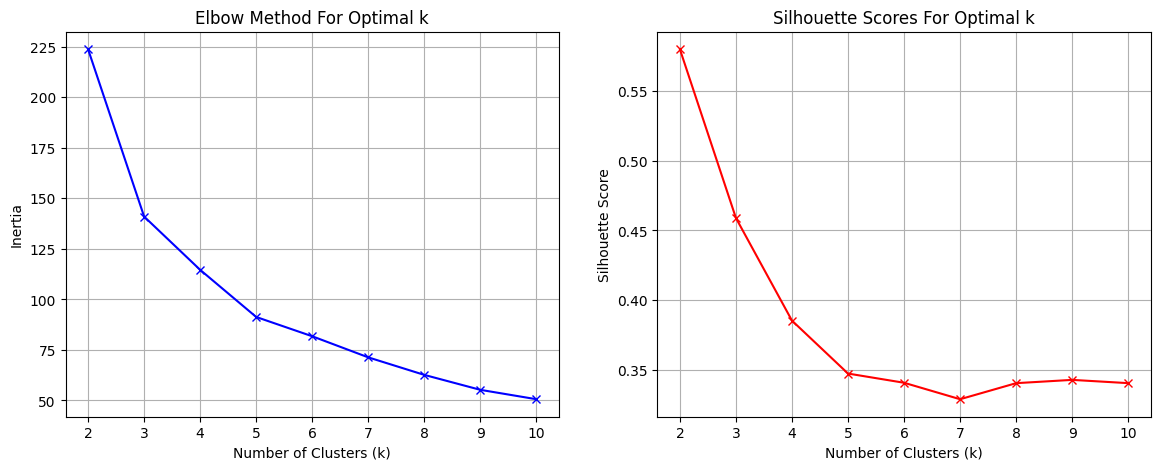

In [3]:
# Determine optimal number of clusters using Elbow Method and Silhouette Score
inertias = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

# Plot Elbow and Silhouette graphs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(K_range, inertias, 'bx-')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')
ax1.set_title('Elbow Method For Optimal k')
ax1.grid(True)

ax2.plot(K_range, silhouette_scores, 'rx-')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Scores For Optimal k')
ax2.grid(True)

plt.show()


In [4]:
# Fit final K-means model with k=3 (since Iris has 3 species)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
y_pred = kmeans.fit_predict(X_scaled)

# Print clustering performance measures
print(f"Inertia: {kmeans.inertia_:.4f}")
print(f"Silhouette Score: {silhouette_score(X_scaled, y_pred):.4f}")


Inertia: 140.9658
Silhouette Score: 0.4590


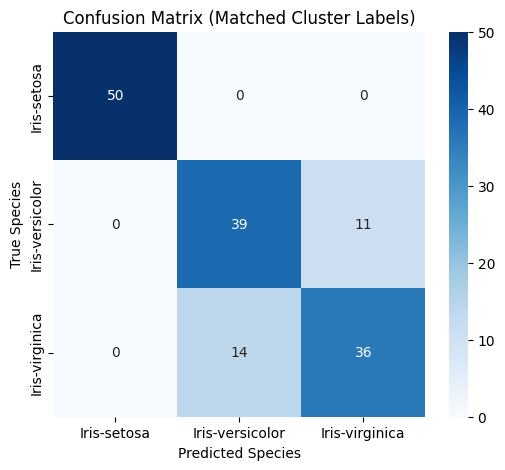

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        50
Iris-versicolor       0.74      0.78      0.76        50
 Iris-virginica       0.77      0.72      0.74        50

       accuracy                           0.83       150
      macro avg       0.83      0.83      0.83       150
   weighted avg       0.83      0.83      0.83       150



In [5]:
from scipy.stats import mode

# Map cluster labels to match true labels for confusion matrix
labels = np.zeros_like(y_pred)
for i in range(3):
    mask = (y_pred == i)
    labels[mask] = mode(y_true[mask], keepdims=True)[0][0]

# Generate Confusion Matrix
cm = confusion_matrix(y_true, labels)
class_names = le.classes_

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix (Matched Cluster Labels)')
plt.xlabel('Predicted Species')
plt.ylabel('True Species')
plt.show()

print(classification_report(y_true, labels, target_names=class_names))


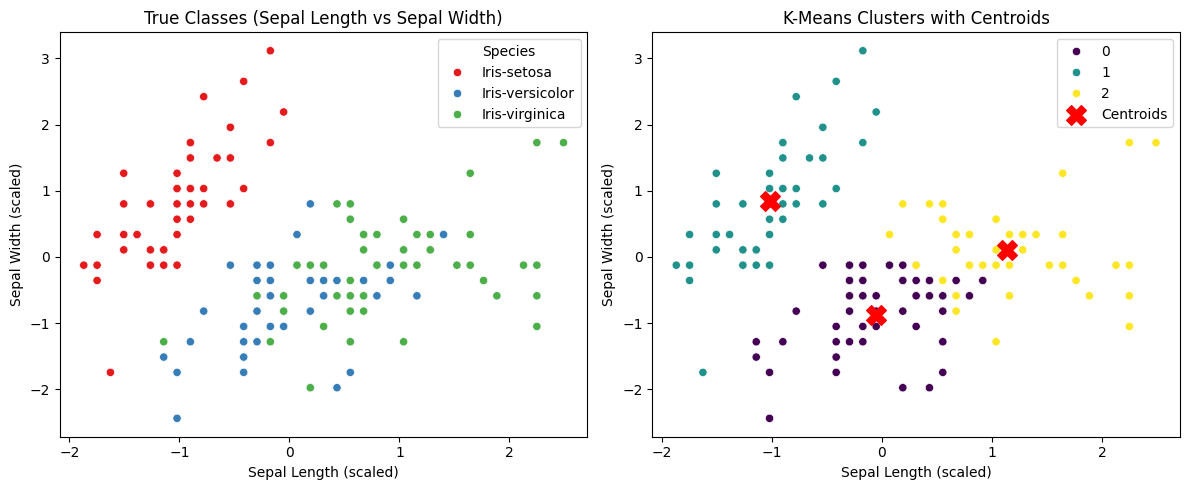

In [6]:
# Visualize the clusters
plt.figure(figsize=(12, 5))

# Plot true classes
plt.subplot(1, 2, 1)
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1], hue=y_true_labels, palette='Set1')
plt.title('True Classes (Sepal Length vs Sepal Width)')
plt.xlabel('Sepal Length (scaled)')
plt.ylabel('Sepal Width (scaled)')

# Plot KMeans clusters with centroids
plt.subplot(1, 2, 2)
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1], hue=y_pred, palette='viridis', legend='full')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=200, c='red', marker='X', label='Centroids')
plt.title('K-Means Clusters with Centroids')
plt.xlabel('Sepal Length (scaled)')
plt.ylabel('Sepal Width (scaled)')
plt.legend()

plt.tight_layout()
plt.show()
